# 05 · Fraud floor simulation (Jul–Dec 2020, the sealed test months)

The model and the £-optimal policy were chosen on **validation** data. Now we replay the **test** months **day by day**, with a team that can only review a fixed number of alerts per day.

- Declined payments become **alerts**. Analysts review the riskiest first; whatever they don't reach waits until tomorrow (**backlog**).
- A **genuine** customer whose payment was declined stays **blocked until an analyst reviews it**, so waiting time = customer harm.
- We compare staffing plans, including a **Christmas surge** and **overflow to step-up** (when the queue is full, borderline alerts get a passcode instead of a decline).

Run cells one at a time.

In [1]:
# 1. Load test-period scores and the policy chosen on validation data
import json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

P = json.load(open("outputs/best_policy.json"))
s = pd.read_parquet("data/clean/scores.parquet")
test = s[s["period"] == "test"].copy()
test["day"] = test["ts"].dt.normalize()
days = sorted(test["day"].unique())

WAIT_COST_PER_DAY = 5.0   # £ harm per genuine customer per day their card stays blocked (illustrative)

test["action"] = np.select([test["score"] >= P["t_decline"], test["score"] >= P["t_step"]],
                           ["decline", "step_up"], default="approve")
alerts_per_day = test[test["action"] == "decline"].groupby("day").size().reindex(days, fill_value=0)
print("Policy:", {k: P[k] for k in ["t_step", "t_decline"]})
print(f"Test: {len(test):,} transactions over {len(days)} days | fraud rate {test['is_fraud'].mean()*100:.3f}%")
print(f"Alerts per day: average {alerts_per_day.mean():.1f} | busiest day {alerts_per_day.max()} "
      f"| December average {alerts_per_day[alerts_per_day.index.month == 12].mean():.1f}")

Policy: {'t_step': 0.005, 't_decline': 0.1}
Test: 525,661 transactions over 184 days | fraud rate 0.383%
Alerts per day: average 13.0 | busiest day 43 | December average 13.1


In [2]:
# 2. The simulator
def simulate(capacity_by_day, overflow_to_stepup=False):
    """capacity_by_day: function(day) -> number of alerts analysts can review that day."""
    t = test.copy()
    queue = pd.DataFrame(columns=["score", "is_fraud", "amt", "created"])
    waits, backlog, extra_step = [], [], []
    for d in days:
        cap = capacity_by_day(d)
        new = t[(t["day"] == d) & (t["action"] == "decline")][["score", "is_fraud", "amt"]].assign(created=d)
        if overflow_to_stepup and len(new) + len(queue) > cap:
            room = max(cap - len(queue), 0)
            new = new.sort_values("score", ascending=False)
            spill = new.iloc[room:]
            extra_step.append(spill.index)              # these become step-ups instead of declines
            new = new.iloc[:room]
        queue = pd.concat([queue, new]) if len(queue) else new
        queue = queue.sort_values("score", ascending=False)  # riskiest first
        done, queue = queue.iloc[:cap], queue.iloc[cap:]
        waits += list(zip((d - done["created"]).dt.days, done["is_fraud"]))
        backlog.append(len(queue))
    waits += list(zip((days[-1] - queue["created"]).dt.days + 1, queue["is_fraud"]))   # never reviewed
    if extra_step:
        idx = np.concatenate([np.asarray(i) for i in extra_step])
        t.loc[idx, "action"] = "step_up"

    fraud, amt, act = t["is_fraud"].values == 1, t["amt"].values, t["action"].values
    fraud_loss = amt[fraud & (act == "approve")].sum() + (1 - P["STEPUP_STOPS_FRAUD"]) * amt[fraud & (act == "step_up")].sum()
    false_declines = ((act == "decline") & ~fraud).sum()
    w = pd.DataFrame(waits, columns=["wait_days", "is_fraud"])
    genuine_wait_days = w.loc[w["is_fraud"] == 0, "wait_days"].sum()
    staff_cost = P["REVIEW_COST"] * sum(capacity_by_day(d) for d in days)
    friction = (P["FALSE_DECLINE_COST"] * false_declines + P["STEPUP_FRICTION"] * ((act == "step_up") & ~fraud).sum()
                + WAIT_COST_PER_DAY * genuine_wait_days)
    return {"fraud_loss": fraud_loss, "staff_cost": staff_cost, "customer_friction": friction,
            "total_cost": fraud_loss + staff_cost + friction,
            "fraud_value_stopped_%": 100 * (1 - fraud_loss / amt[fraud].sum()),
            "avg_wait_days": w["wait_days"].mean(), "max_backlog": max(backlog),
            "genuine_blocked_overnight": int(((w["is_fraud"] == 0) & (w["wait_days"] >= 1)).sum()),
            "backlog_series": backlog}
print("Simulator ready ✅")

Simulator ready ✅


In [3]:
# 3. Compare staffing plans
base = int(np.ceil(alerts_per_day.mean()))
plans = {
    f"Lean: {base - 4}/day":              lambda d: base - 4,
    f"Average demand: {base}/day":        lambda d: base,
    f"Generous: {base + 10}/day":         lambda d: base + 10,
    f"Christmas surge: {base}/day, x2 in Dec": lambda d: base * 2 if pd.Timestamp(d).month == 12 else base,
}
results = {name: simulate(cap) for name, cap in plans.items()}
results[f"Overflow to step-up: {base}/day"] = simulate(lambda d: base, overflow_to_stepup=True)

table = pd.DataFrame({k: {m: v for m, v in r.items() if m != "backlog_series"} for k, r in results.items()}).T
table["total_cost_per_month"] = table["total_cost"] / len(days) * 30
table.to_csv("outputs/simulation_plans.csv")
table[["total_cost_per_month", "fraud_value_stopped_%", "avg_wait_days", "max_backlog",
       "genuine_blocked_overnight", "fraud_loss", "staff_cost", "customer_friction"]].round(1)

,total_cost_per_month,fraud_value_stopped_%,avg_wait_days,max_backlog,genuine_blocked_overnight,fraud_loss,staff_cost,customer_friction
Lean: 9/day,44502.0,95.4,30.8,787.0,589.0,48343.1,4968.0,219634.5
Average demand: 13/day,16880.5,95.4,4.9,135.0,377.0,48343.1,7176.0,48014.5
Generous: 23/day,11412.8,95.4,0.1,21.0,63.0,48343.1,12696.0,8959.5
"Christmas surge: 13/day, x2 in Dec",15248.3,95.4,3.8,121.0,278.0,48343.1,8385.0,36794.5
Overflow to step-up: 13/day,14725.7,92.8,0.0,0.0,0.0,76793.8,7176.0,6347.5


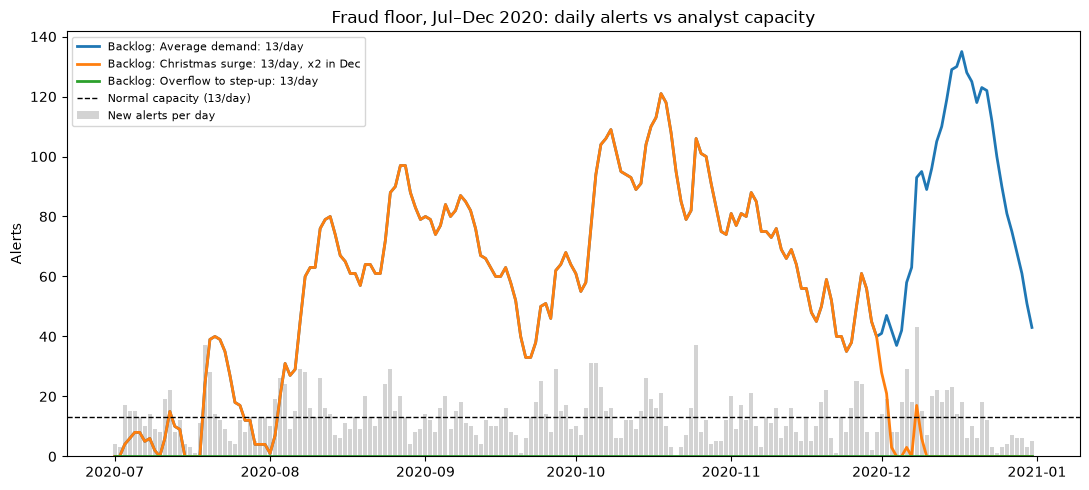

In [4]:
# 4. The picture: alerts vs capacity and backlog, day by day
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(days, alerts_per_day.values, color="lightgray", label="New alerts per day")
for name in [f"Average demand: {base}/day", f"Christmas surge: {base}/day, x2 in Dec", f"Overflow to step-up: {base}/day"]:
    ax.plot(days, results[name]["backlog_series"], linewidth=2, label=f"Backlog: {name}")
ax.axhline(base, color="black", linestyle="--", linewidth=1, label=f"Normal capacity ({base}/day)")
ax.set_title("Fraud floor, Jul–Dec 2020: daily alerts vs analyst capacity")
ax.set_ylabel("Alerts"); ax.legend(fontsize=8); plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/simulation_backlog.png", dpi=150); plt.show()

Cheapest staffing level for each customer-harm assumption:
 wait_cost_£_per_day  capacity_per_day  cost_per_month  avg_wait_days  genuine_blocked_overnight
                   1                15         10896.5            1.2                        274
                   5                21         11320.9            0.2                         89
                  10                21         11484.7            0.2                         89


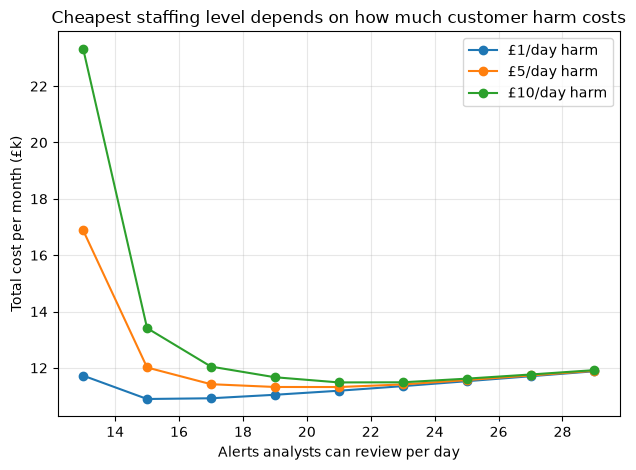

In [5]:
# 5. Find the cheapest staffing level, and test it against the customer-harm assumption
sweep = []
for wait_cost in [1, 5, 10]:
    WAIT_COST_PER_DAY = wait_cost
    for cap in range(13, 31, 2):
        r = simulate(lambda d, c=cap: c)
        sweep.append({"wait_cost_£_per_day": wait_cost, "capacity_per_day": cap,
                      "cost_per_month": r["total_cost"] / len(days) * 30,
                      "avg_wait_days": r["avg_wait_days"], "genuine_blocked_overnight": r["genuine_blocked_overnight"]})
WAIT_COST_PER_DAY = 5.0
sweep = pd.DataFrame(sweep)
sweep.to_csv("outputs/staffing_sweep.csv", index=False)

best = sweep.loc[sweep.groupby("wait_cost_£_per_day")["cost_per_month"].idxmin()]
print("Cheapest staffing level for each customer-harm assumption:")
print(best.round(1).to_string(index=False))

for wc, g in sweep.groupby("wait_cost_£_per_day"):
    plt.plot(g["capacity_per_day"], g["cost_per_month"] / 1000, marker="o", label=f"£{wc}/day harm")
plt.xlabel("Alerts analysts can review per day"); plt.ylabel("Total cost per month (£k)")
plt.title("Cheapest staffing level depends on how much customer harm costs")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("outputs/staffing_sweep.png", dpi=150); plt.show()